Total train points: 1050 | Total test points: 300

Class 1: n_train = 350, n_test = 100
Mean: [ 411.93668571 1222.83828571]
Covariance:
 [[ 21921.66551816  35638.38376718]
 [ 35638.38376718 161797.53982278]]

Class 2: n_train = 350, n_test = 100
Mean: [ 335.968      2040.57542857]
Covariance:
 [[ 6152.62929714 -5602.93720629]
 [-5602.93720629 40103.58922482]]

Class 3: n_train = 350, n_test = 100
Mean: [ 585.04214286 1430.04622857]
Covariance:
 [[21274.07627169 -6171.19124649]
 [-6171.19124649 34141.99625892]]

Correct predictions: 255 / 300
Accuracy: 0.8500  (85.00%)

First 10 test predictions:
Point: [347.88 710.39] Actual: 1 Predicted: 1
Point: [ 387.1 1121.3] Actual: 1 Predicted: 1
Point: [436.84 859.81] Actual: 1 Predicted: 1
Point: [ 500. 1500.] Actual: 1 Predicted: 3
Point: [319.66 739.62] Actual: 1 Predicted: 1
Point: [210.55 745.53] Actual: 1 Predicted: 1
Point: [ 500. 1500.] Actual: 1 Predicted: 3
Point: [ 500. 1500.] Actual: 1 Predicted: 3
Point: [353.36 865.19] Actual: 1 Pr

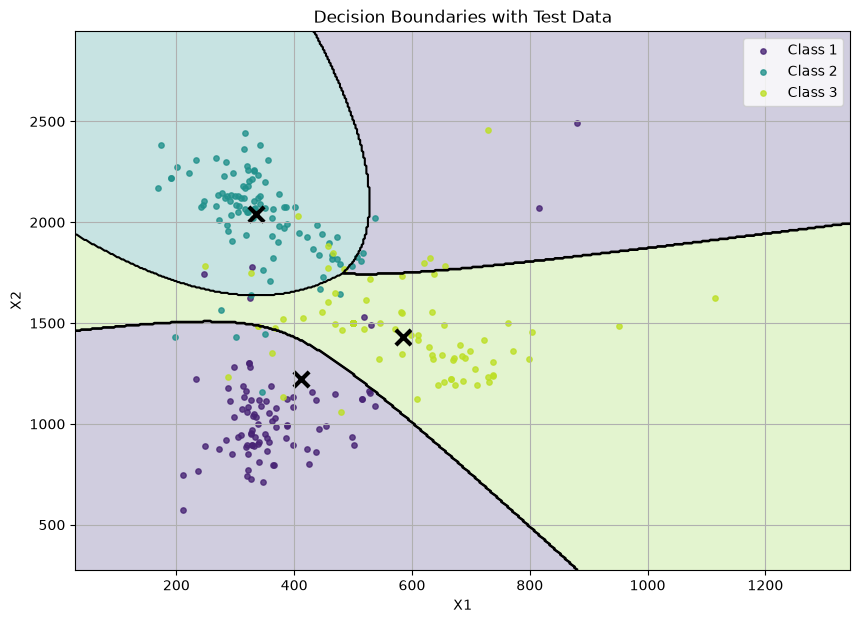


ROC (one-vs-rest) AUC:
  Class 1: AUC = 0.9484   (max TP = 100, max FP = 200)
  Class 2: AUC = 0.9794   (max TP = 100, max FP = 200)
  Class 3: AUC = 0.9419   (max TP = 100, max FP = 200)


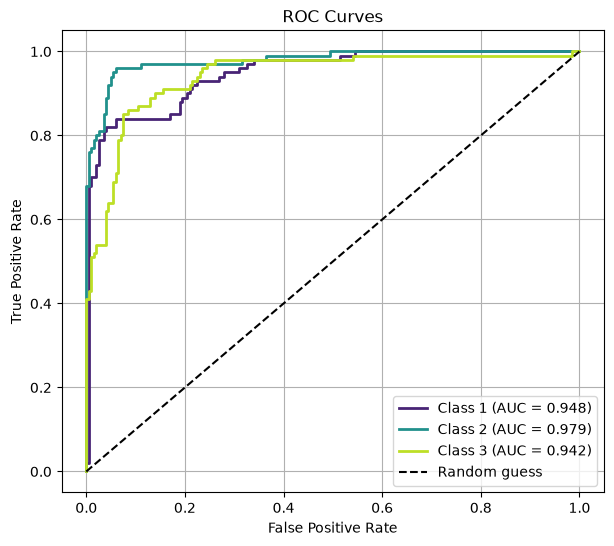

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# load data
train = np.loadtxt("trian.txt", delimiter=",")   
test  = np.loadtxt("dev.txt",   delimiter=",")
Xtr, ytr = train[:, :2], train[:, 2].astype(int)
Xte, yte = test[:, :2],  test[:, 2].astype(int)
classes = [1, 2, 3]

# MLE
mus, covs, priors = [], [], []
print("Total train points:", len(Xtr), "| Total test points:", len(Xte))
for c in classes:
    Xc = Xtr[ytr == c]
    mus.append(Xc.mean(axis=0))
    covs.append(np.cov(Xc, rowvar=False, bias=True))   # divide by n
    priors.append(len(Xc) / len(Xtr))
    print(f"\nClass {c}: n_train = {len(Xc)}, n_test = {(yte == c).sum()}")
    print("Mean:", mus[-1])
    print("Covariance:\n", covs[-1])


def log_gaussian(P, mu, cov):
    d = P.shape[1]
    diff = P - mu
    _, logdet = np.linalg.slogdet(cov)
    quad = np.einsum("ij,ij->i", diff @ np.linalg.inv(cov), diff)
    return -0.5 * (d * np.log(2 * np.pi) + logdet + quad)

def predict(P, use_priors=False):
    scores = np.column_stack([
        log_gaussian(P, mus[k], covs[k]) + (np.log(priors[k]) if use_priors else 0.0)
        for k in range(3)])
    return scores.argmax(axis=1) + 1


pred = predict(Xte)
correct = int((pred == yte).sum())
print(f"\nCorrect predictions: {correct} / {len(yte)}")
print(f"Accuracy: {correct / len(yte):.4f}  ({100 * correct / len(yte):.2f}%)")

print("\nFirst 10 test predictions:")
for i in range(min(10, len(yte))):
    print("Point:", Xte[i], "Actual:", yte[i], "Predicted:", pred[i])

cm = np.zeros((3, 3), dtype=int)
for a, p in zip(yte, pred):
    cm[a - 1, p - 1] += 1
print("\nConfusion Matrix (rows = actual, cols = predicted):")
print("              Predicted")
print("             C1    C2    C3")
for i in range(3):
    print(f"Actual C{i + 1}   ", cm[i])

pad_x = 0.1 * np.ptp(Xtr[:, 0])
pad_y = 0.1 * np.ptp(Xtr[:, 1])
gx, gy = np.meshgrid(
    np.linspace(Xtr[:, 0].min() - pad_x, Xtr[:, 0].max() + pad_x, 500),
    np.linspace(Xtr[:, 1].min() - pad_y, Xtr[:, 1].max() + pad_y, 500))
grid = np.column_stack([gx.ravel(), gy.ravel()])
region = predict(grid).reshape(gx.shape)

cmap = plt.get_cmap("viridis")
class_colors = [cmap(v) for v in (0.1, 0.5, 0.9)]   # match scatter colors to the regions

plt.figure(figsize=(10, 7))
plt.contourf(gx, gy, region, levels=[0.5, 1.5, 2.5, 3.5], cmap="viridis", alpha=0.25)
plt.contour(gx, gy, region, levels=[1.5, 2.5], colors="k", linewidths=1.5)
for c, col, mu in zip(classes, class_colors, mus):
    pts = Xte[yte == c]
    plt.scatter(pts[:, 0], pts[:, 1], s=15, color=col, alpha=0.8, label=f"Class {c}")
    plt.scatter(mu[0], mu[1], marker="x", s=120, linewidths=3, color="k")
plt.xlabel("X1")
plt.ylabel("X2")
plt.title("Decision Boundaries with Test Data")
plt.legend()
plt.grid(True)
plt.show()


#ROC CURVE
def posteriors(points, mus, covs):
    ll = np.array([log_gaussian(points, m, c) for m, c in zip(mus, covs)])
    ll -= ll.max(axis=0)
    p = np.exp(ll)
    return p / p.sum(axis=0)

def roc_curve(is_positive, score):
    order = np.argsort(-score)
    y = is_positive[order].astype(float)
    P = y.sum()
    N = len(y) - P
    tp = np.concatenate([[0], np.cumsum(y)])
    fp = np.concatenate([[0], np.cumsum(1 - y)])
    tpr = tp / P
    fpr = fp / N
    auc = np.sum(np.diff(fpr) * (tpr[1:] + tpr[:-1]) / 2)
    return fp, tp, fpr, tpr, auc

def plot_roc(actual, post):
    plt.figure(figsize=(7, 6))
    print("\nROC (one-vs-rest) AUC:")
    for k in range(post.shape[0]):
        fp, tp, fpr, tpr, auc = roc_curve(actual == k + 1, post[k])
        print(f"  Class {k + 1}: AUC = {auc:.4f}   "
              f"(max TP = {int(tp[-1])}, max FP = {int(fp[-1])})")
        plt.plot(fpr, tpr, linewidth=2, color=class_colors[k],
                 label=f"Class {k + 1} (AUC = {auc:.3f})")
    plt.plot([0, 1], [0, 1], "k--", label="Random guess")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curves")
    plt.legend(loc="lower right")
    plt.grid(True)
    plt.show()

post = posteriors(Xte, mus, covs)
plot_roc(yte, post)